# Chicago Taxi Fare Regression with scikit-learn

**A hands-on regression lab with scikit-learn**

---

In this lab, we will build and evaluate regression models for predicting Chicago taxi fares with scikit-learn.  We will work through each step explicitly so that we understand what the data, transformations, models, and evaluation metrics are doing. After the manual implementations, we will revisit the same ideas using Pipeline as an optional final exercise.

The goal here is not to hide machine learning behind a convenient API. The goal is to understand the pieces.

> *Important: In the main part of this exercise, do not use Pipeline. For each model, you will explicitly perform the necessary preprocessing, create the model, fit it, predict with it, and evaluate it. Only after you understand those steps will you repeat the same three models using Pipeline as an optional final exercise.*



# Part 1: Setup



## 1.1 Install and import the libraries

In [1]:
!pip install -q scikit-learn pandas numpy matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 1.2 Load the dataset

In [3]:
chicago_taxi_dataset = pd.read_csv("https://download.mlcc.google.com/mledu-datasets/chicago_taxi_train.csv")

print(f"Rows: {len(chicago_taxi_dataset):,}")
print(f"Columns: {len(chicago_taxi_dataset.columns)}")

Rows: 31,694
Columns: 18


## 1.3 Keep the columns that are relevant to the exercise

In [4]:
training_df = chicago_taxi_dataset.loc[:, [
    "TRIP_MILES",
    "TRIP_SECONDS",
    "FARE",
    "COMPANY",
    "PAYMENT_TYPE",
    "TIP_RATE",
]].copy()

training_df.head()

,TRIP_MILES,TRIP_SECONDS,FARE,COMPANY,PAYMENT_TYPE,TIP_RATE
0,2.57,2341,31.99,Flash Cab,Mobile,6.3
1,1.18,1074,9.75,Flash Cab,Credit Card,27.9
2,1.29,1173,10.25,Sun Taxi,Cash,0.0
3,3.70,3360,23.75,Choice Taxi Association,Cash,0.0
4,1.15,1044,10.00,Flash Cab,Cash,0.0


## 1.4 Create trip duration in minutes

In [5]:
training_df["TRIP_MINUTES"] = training_df["TRIP_SECONDS"] / 60

training_df[["TRIP_SECONDS", "TRIP_MINUTES"]].head()

,TRIP_SECONDS,TRIP_MINUTES
0,2341,39.016667
1,1074,17.900000
2,1173,19.550000
3,3360,56.000000
4,1044,17.400000


# Part 2: Explore the data before modeling

## 2.1 Inspect basic statistics

In [6]:
training_df.describe(include="all")

,TRIP_MILES,TRIP_SECONDS,FARE,COMPANY,PAYMENT_TYPE,TIP_RATE,TRIP_MINUTES
count,31694.000000,31694.000000,31694.000000,31694,31694,31694.000000,31694.000000
unique,NaN,NaN,NaN,31,7,NaN,NaN
top,NaN,NaN,NaN,Flash Cab,Credit Card,NaN,NaN
freq,NaN,NaN,NaN,7887,14142,NaN,NaN
mean,8.289463,1319.796397,23.905210,NaN,NaN,12.965785,21.996607
std,7.265672,928.932873,16.970022,NaN,NaN,15.517765,15.482215
min,0.500000,60.000000,3.250000,NaN,NaN,0.000000,1.000000
25%,1.720000,548.000000,9.000000,NaN,NaN,0.000000,9.133333
50%,5.920000,1081.000000,18.750000,NaN,NaN,12.200000,18.016667
75%,14.500000,1888.000000,38.750000,NaN,NaN,20.800000,31.466667


In [7]:
max_fare = training_df["FARE"].max()
avg_distance = training_df["TRIP_MILES"].mean()
unique_companies = training_df["COMPANY"].nunique()
common_payment_type = training_df["PAYMENT_TYPE"].value_counts().idxmax()
missing_values = training_df.isna().sum()

print("Maximum fare:", max_fare)
print("Average trip distance:", avg_distance)
print("Number of unique taxi companies:", unique_companies)
print("Most common payment type:", common_payment_type)
print("Missing values:\n", missing_values)

Maximum fare: 159.25
Average trip distance: 8.289462674323214
Number of unique taxi companies: 31
Most common payment type: Credit Card
Missing values:
 TRIP_MILES      0
TRIP_SECONDS    0
FARE            0
COMPANY         0
PAYMENT_TYPE    0
TIP_RATE        0
TRIP_MINUTES    0
dtype: int64


## 2.2 Inspect correlations

In [8]:
correlation_matrix = training_df.corr(numeric_only=True)
correlation_matrix

,TRIP_MILES,TRIP_SECONDS,FARE,TIP_RATE,TRIP_MINUTES
TRIP_MILES,1.000000,0.800855,0.975344,-0.049594,0.800855
TRIP_SECONDS,0.800855,1.000000,0.830292,-0.084294,1.000000
FARE,0.975344,0.830292,1.000000,-0.070979,0.830292
TIP_RATE,-0.049594,-0.084294,-0.070979,1.000000,-0.084294
TRIP_MINUTES,0.800855,1.000000,0.830292,-0.084294,1.000000


In [9]:
fare_correlations = correlation_matrix["FARE"].sort_values(ascending=False)
fare_correlations

,FARE
FARE,1.000000
TRIP_MILES,0.975344
TRIP_SECONDS,0.830292
TRIP_MINUTES,0.830292
TIP_RATE,-0.070979


Question 1: Which feature has the strongest correlation with FARE?

- TRIP_MILES

Question 2: Does a high correlation automatically mean a feature is always useful in a machine-learning model?

- No.

Question 3: Why might TRIP_SECONDS and TRIP_MINUTES be highly correlated with each other?

- Because they contain the same information.

## 2.3 Visualize the data

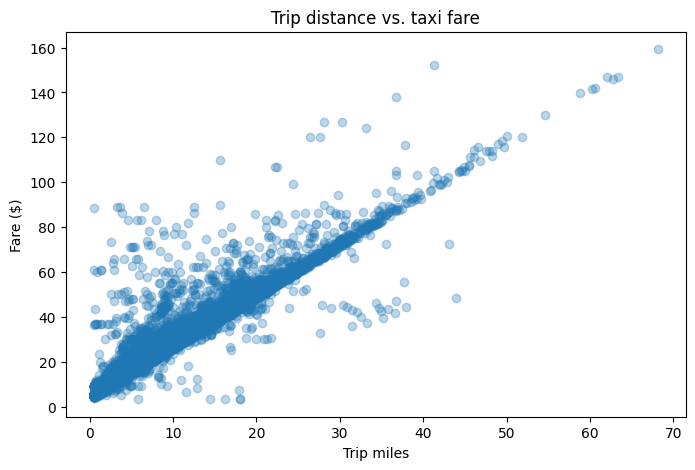

In [10]:
# Distance vs. fare
plt.figure(figsize=(8, 5))
plt.scatter(training_df["TRIP_MILES"], training_df["FARE"], alpha=0.3)
plt.xlabel("Trip miles")
plt.ylabel("Fare ($)")
plt.title("Trip distance vs. taxi fare")
plt.show()

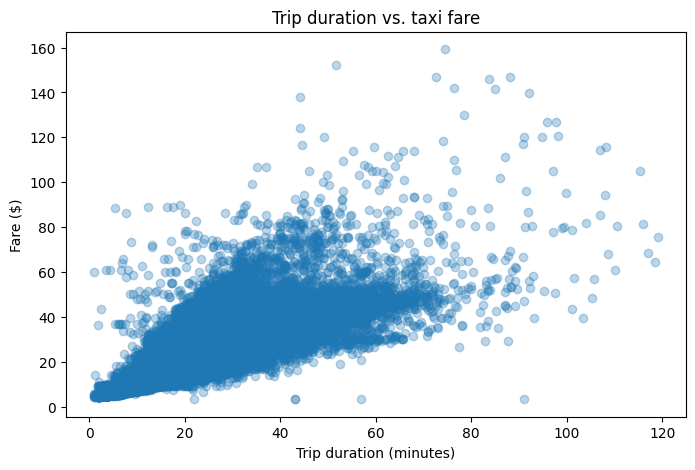

In [11]:
# Duration vs. fare
plt.figure(figsize=(8, 5))
plt.scatter(training_df["TRIP_MINUTES"], training_df["FARE"], alpha=0.3)
plt.xlabel("Trip duration (minutes)")
plt.ylabel("Fare ($)")
plt.title("Trip duration vs. taxi fare")
plt.show()

# Part 3: A common evaluation procedure

## 3.1 Define features and target

In [12]:
X = training_df[["TRIP_MILES"]]
y = training_df["FARE"]

## 3.2 Split the data

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

## 3.3 Create a small evaluation helper

In [15]:
def evaluate_regression(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"MAE : ${mae:.2f}")
    print(f"RMSE: ${rmse:.2f}")
    print(f"R²  : {r2:.4f}")

# Part 4: Model 1: Simple Linear Regression

## 4.1 Step 1: Select the feature and label

In [16]:
X = training_df[["TRIP_MILES"]]
y = training_df["FARE"]

## 4.2 Step 2: Split the data

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42,)

## 4.3 Step 3: Create the model

In [18]:
model_lr_1 = LinearRegression()

## 4.4 Step 4: Train the model

In [19]:
model_lr_1.fit(X_train, y_train)

LinearRegression()

In [20]:
print("Coefficient:", model_lr_1.coef_[0])
print("Intercept:", model_lr_1.intercept_)

Coefficient: 2.2751270662289755
Intercept: 5.038586379833486


## 4.5 Step 5: Predict

In [21]:
y_pred_lr_1 = model_lr_1.predict(X_test)

## 4.6 Step 6: Evaluate

In [22]:
evaluate_regression(y_test, y_pred_lr_1)

MAE : $1.58
RMSE: $3.85
R²  : 0.9499


## 4.7 Step 7: Visualize predictions

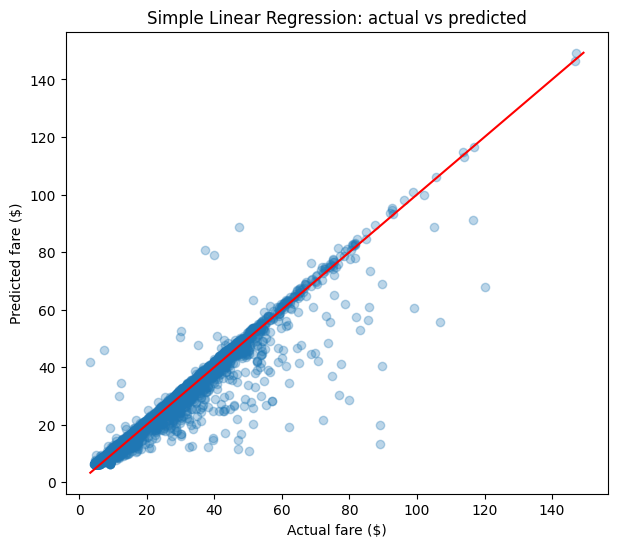

In [27]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_lr_1, alpha=0.3)

min_fare = min(y_test.min(), y_pred_lr_1.min())
max_fare = max(y_test.max(), y_pred_lr_1.max())
plt.plot([min_fare, max_fare], [min_fare, max_fare], color="red")

plt.xlabel("Actual fare ($)")
plt.ylabel("Predicted fare ($)")
plt.title("Simple Linear Regression: actual vs predicted")
plt.show()

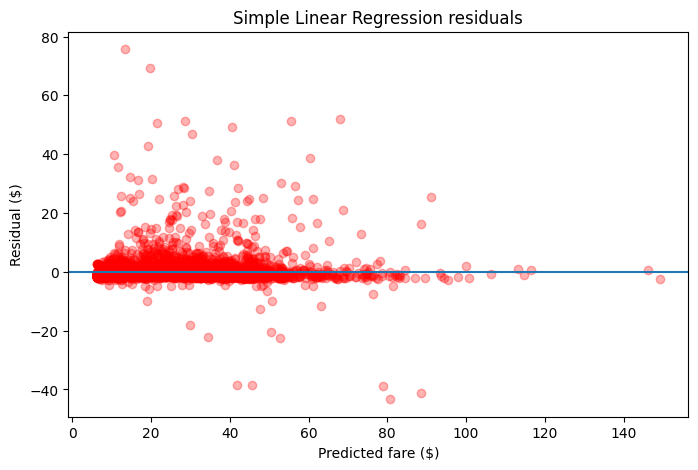

In [30]:
residuals_lr_1 = y_test - y_pred_lr_1

plt.figure(figsize=(8, 5))
plt.scatter(y_pred_lr_1, residuals_lr_1, alpha=0.3, color="red")
plt.axhline(0)
plt.xlabel("Predicted fare ($)")
plt.ylabel("Residual ($)")
plt.title("Simple Linear Regression residuals")
plt.show()

# Part 5: Model 2 - Multiple Linear Regression

## 5.1 Step 1: Select two features

In [31]:
X = training_df[["TRIP_MILES", "TRIP_MINUTES"]]
y = training_df["FARE"]

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

In [33]:
model_lr_2 = LinearRegression()

In [34]:
model_lr_2.fit(X_train, y_train)

LinearRegression()

In [35]:
print("Intercept:", model_lr_2.intercept_)

for feature, coefficient in zip(X.columns, model_lr_2.coef_):
    print(f"{feature}: {coefficient}")

Intercept: 3.8570500516288178
TRIP_MILES: 2.016342440221902
TRIP_MINUTES: 0.1510898825885126


In [36]:
y_pred_lr_2 = model_lr_2.predict(X_test)

In [37]:
evaluate_regression(y_test, y_pred_lr_2)

MAE : $1.21
RMSE: $3.60
R²  : 0.9561


## 5.8 Compare Model 1 and Model 2

In [38]:
results_manual = pd.DataFrame({
    "Model": [
        "Linear Regression — TRIP_MILES",
        "Multiple Linear Regression — TRIP_MILES + TRIP_MINUTES",
    ],
    "MAE": [
        mean_absolute_error(y_test, y_pred_lr_1),
        mean_absolute_error(y_test, y_pred_lr_2),
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_lr_1)),
        np.sqrt(mean_squared_error(y_test, y_pred_lr_2)),
    ],
    "R2": [
        r2_score(y_test, y_pred_lr_1),
        r2_score(y_test, y_pred_lr_2),
    ],
})

results_manual

,Model,MAE,RMSE,R2
0,Linear Regression — TRIP_MILES,1.582518,3.850788,0.949870
1,Multiple Linear Regression — TRIP_MILES + TRIP...,1.206448,3.604573,0.956076


# Part 6: Model 3: Polynomial Regression

## 6.2 Start with one feature for clarity

In [39]:
X = training_df[["TRIP_MILES"]]
y = training_df["FARE"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

## 6.3 Create the polynomial transformer

In [40]:
poly = PolynomialFeatures(degree=2, include_bias=False)

## 6.4 Transform the training data

In [41]:
X_train_poly = poly.fit_transform(X_train)

In [42]:
print("Original shape:", X_train.shape)
print("Polynomial shape:", X_train_poly.shape)

Original shape: (25355, 1)
Polynomial shape: (25355, 2)


## 6.5 Transform the test data

In [43]:
X_test_poly = poly.transform(X_test)

## 6.6 Inspect the transformed features

In [44]:
print(X_train_poly[:5])

[[  2.06     4.2436]
 [  9.53    90.8209]
 [  1.1      1.21  ]
 [ 17.6    309.76  ]
 [ 15.61   243.6721]]


## 6.7 Create the linear regression model

In [45]:
model_poly_2 = LinearRegression()

In [46]:
model_poly_2.fit(X_train_poly, y_train)

LinearRegression()

In [47]:
y_pred_poly_2 = model_poly_2.predict(X_test_poly)

In [48]:
evaluate_regression(y_test, y_pred_poly_2)

MAE : $1.57
RMSE: $3.84
R²  : 0.9502


In [49]:
print("Linear Regression")
evaluate_regression(y_test, y_pred_lr_1)

print("\nPolynomial Regression (degree=2)")
evaluate_regression(y_test, y_pred_poly_2)

Linear Regression
MAE : $1.58
RMSE: $3.85
R²  : 0.9499

Polynomial Regression (degree=2)
MAE : $1.57
RMSE: $3.84
R²  : 0.9502


## 6.11 Visualize the polynomial curve

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


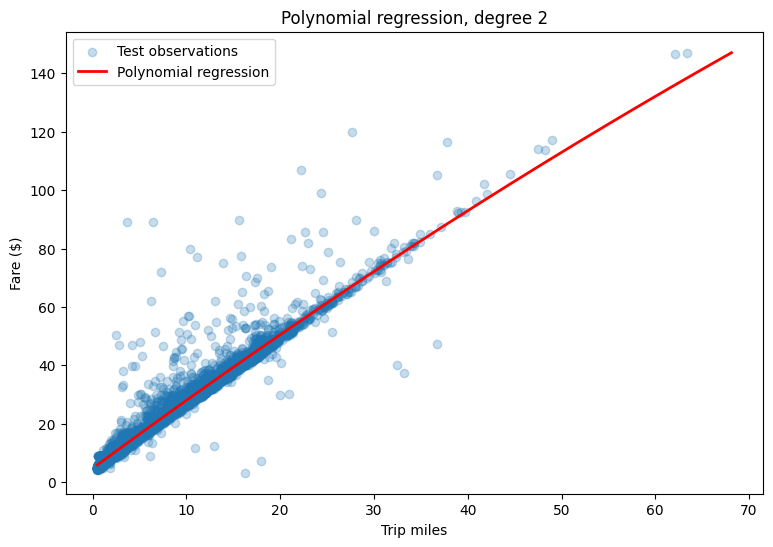

In [51]:
x_curve = np.linspace(
    X["TRIP_MILES"].min(),
    X["TRIP_MILES"].max(),
    300,
).reshape(-1, 1)

x_curve_poly = poly.transform(x_curve)
y_curve = model_poly_2.predict(x_curve_poly)

plt.figure(figsize=(9, 6))
plt.scatter(X_test["TRIP_MILES"], y_test, alpha=0.25, label="Test observations")
plt.plot(x_curve, y_curve, linewidth=2, label="Polynomial regression", color="red")
plt.xlabel("Trip miles")
plt.ylabel("Fare ($)")
plt.title("Polynomial regression, degree 2")
plt.legend()
plt.show()

# Part 7: Polynomial Regression with two original features

## 7.1 Prepare the data

In [52]:
X = training_df[["TRIP_MILES", "TRIP_MINUTES"]]
y = training_df["FARE"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

## 7.2 Create and fit the transformer

In [53]:
poly_2_features = PolynomialFeatures(
    degree=2,
    include_bias=False,
)

X_train_poly_2_features = poly_2_features.fit_transform(X_train)
X_test_poly_2_features = poly_2_features.transform(X_test)

In [54]:
poly_feature_names = poly_2_features.get_feature_names_out(X.columns)
print(poly_feature_names)

['TRIP_MILES' 'TRIP_MINUTES' 'TRIP_MILES^2' 'TRIP_MILES TRIP_MINUTES'
 'TRIP_MINUTES^2']


## 7.3 Train


In [55]:
model_poly_2_features = LinearRegression()
model_poly_2_features.fit(X_train_poly_2_features, y_train)

LinearRegression()

## 7.4 Predict


In [58]:
y_pred_poly_2_features = model_poly_2_features.predict(X_test_poly_2_features)


## 7.5 Evaluate



In [59]:
evaluate_regression(y_test, y_pred_poly_2_features)

MAE : $1.11
RMSE: $3.57
R²  : 0.9570


## 7.6 Inspect the learned coefficients


In [60]:
print("Intercept:", model_poly_2_features.intercept_)

for name, coefficient in zip(
    poly_feature_names,
    model_poly_2_features.coef_,
):
    print(f"{name:30s} {coefficient: .6f}")

Intercept: 3.699196233531943
TRIP_MILES                      2.073900
TRIP_MINUTES                    0.148354
TRIP_MILES^2                    0.009106
TRIP_MILES TRIP_MINUTES        -0.009476
TRIP_MINUTES^2                  0.001681


# Part 8: Compare the three approaches

In [61]:
comparison = pd.DataFrame({
    "Model": [
        "Linear — 1 feature",
        "Linear — 2 features",
        "Polynomial degree 2 — 1 feature",
        "Polynomial degree 2 — 2 features",
    ],
    "MAE": [
        mean_absolute_error(y_test, y_pred_lr_1),
        mean_absolute_error(y_test, y_pred_lr_2),
        mean_absolute_error(y_test, y_pred_poly_2),
        mean_absolute_error(y_test, y_pred_poly_2_features),
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_lr_1)),
        np.sqrt(mean_squared_error(y_test, y_pred_lr_2)),
        np.sqrt(mean_squared_error(y_test, y_pred_poly_2)),
        np.sqrt(mean_squared_error(y_test, y_pred_poly_2_features)),
    ],
    "R2": [
        r2_score(y_test, y_pred_lr_1),
        r2_score(y_test, y_pred_lr_2),
        r2_score(y_test, y_pred_poly_2),
        r2_score(y_test, y_pred_poly_2_features),
    ],
}).sort_values("RMSE")

comparison

,Model,MAE,RMSE,R2
3,Polynomial degree 2 — 2 features,1.113827,3.566391,0.957001
1,Linear — 2 features,1.206448,3.604573,0.956076
2,Polynomial degree 2 — 1 feature,1.568923,3.837607,0.950213
0,Linear — 1 feature,1.582518,3.850788,0.949870


# Part 9: Hyperparameter experiment: polynomial degree

## 9.1 Experiment code

In [62]:
degree_results = []

X = training_df[["TRIP_MILES"]]
y = training_df["FARE"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

for degree in [1, 2, 3, 4]:
    poly = PolynomialFeatures(
        degree=degree,
        include_bias=False,
    )

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)

    degree_results.append({
        "Degree": degree,
        "Train_RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Train_R2": r2_score(y_train, train_pred),
        "Test_R2": r2_score(y_test, test_pred),
    })

degree_results_df = pd.DataFrame(degree_results)
degree_results_df

,Degree,Train_RMSE,Test_RMSE,Train_R2,Test_R2
0,1,3.718189,3.850788,0.951664,0.949870
1,2,3.704839,3.837607,0.952010,0.950213
2,3,3.687668,3.819050,0.952454,0.950693
3,4,3.678077,3.806750,0.952701,0.951010


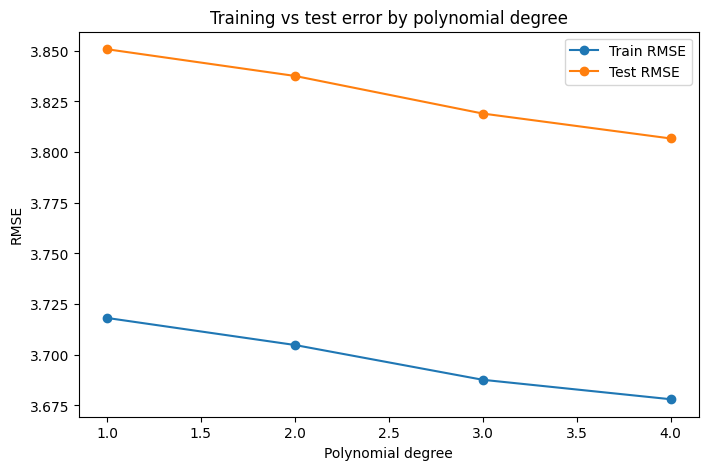

In [63]:
plt.figure(figsize=(8, 5))
plt.plot(
    degree_results_df["Degree"],
    degree_results_df["Train_RMSE"],
    marker="o",
    label="Train RMSE",
)
plt.plot(
    degree_results_df["Degree"],
    degree_results_df["Test_RMSE"],
    marker="o",
    label="Test RMSE",
)
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE")
plt.title("Training vs test error by polynomial degree")
plt.legend()
plt.show()

# Part 12: Pipeline version of Model 1

In [65]:
# Simple linear regression has no preprocessing requirement here, so the pipeline is mostly educational.
pipeline_linear_1 = Pipeline([
    ("model", LinearRegression()),
])

X = training_df[["TRIP_MILES"]]
y = training_df["FARE"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

pipeline_linear_1.fit(X_train, y_train)
y_pred_pipeline_linear_1 = pipeline_linear_1.predict(X_test)

evaluate_regression(y_test, y_pred_pipeline_linear_1)

MAE : $1.58
RMSE: $3.85
R²  : 0.9499


# Part 13: Pipeline version of Model 2

In [66]:
# Multiple linear regression also requires no mandatory transformation for this exercise.
pipeline_linear_2 = Pipeline([
    ("model", LinearRegression()),
])

X = training_df[["TRIP_MILES", "TRIP_MINUTES"]]
y = training_df["FARE"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

pipeline_linear_2.fit(X_train, y_train)
y_pred_pipeline_linear_2 = pipeline_linear_2.predict(X_test)

evaluate_regression(y_test, y_pred_pipeline_linear_2)

MAE : $1.21
RMSE: $3.60
R²  : 0.9561


# Part 14: Pipeline version of Model 3: Polynomial Regression

In [67]:
# This is where the pipeline becomes genuinely useful.
pipeline_poly_2 = Pipeline([
    (
        "polynomial_features",
        PolynomialFeatures(degree=2, include_bias=False),
    ),
    (
        "model",
        LinearRegression(),
    ),
])

X = training_df[["TRIP_MILES"]]
y = training_df["FARE"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

pipeline_poly_2.fit(X_train, y_train)
y_pred_pipeline_poly_2 = pipeline_poly_2.predict(X_test)

evaluate_regression(y_test, y_pred_pipeline_poly_2)

MAE : $1.57
RMSE: $3.84
R²  : 0.9502


# Part 15: Pipeline version with two-feature polynomial regression

In [68]:
# Now combine multiple features and polynomial expansion inside one pipeline.
pipeline_poly_2_features = Pipeline([
    (
        "polynomial_features",
        PolynomialFeatures(degree=2, include_bias=False),
    ),
    (
        "model",
        LinearRegression(),
    ),
])

X = training_df[["TRIP_MILES", "TRIP_MINUTES"]]
y = training_df["FARE"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

pipeline_poly_2_features.fit(X_train, y_train)
y_pred_pipeline_poly_2_features = pipeline_poly_2_features.predict(X_test)

evaluate_regression(y_test, y_pred_pipeline_poly_2_features)

MAE : $1.11
RMSE: $3.57
R²  : 0.9570


### Compare manual and pipeline results

In [69]:
manual_poly_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_poly_2_features)
)

pipeline_poly_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_pipeline_poly_2_features)
)

print("Manual RMSE   :", manual_poly_rmse)
print("Pipeline RMSE :", pipeline_poly_rmse)

Manual RMSE   : 3.5663912035178935
Pipeline RMSE : 3.5663912035178935


# Part 16: Final comparison: manual vs pipeline

In [70]:
final_comparison = pd.DataFrame({
    "Implementation": [
        "Manual",
        "Pipeline",
    ],
    "Model": [
        "Polynomial degree 2, 2 features",
        "Polynomial degree 2, 2 features",
    ],
    "MAE": [
        mean_absolute_error(y_test, y_pred_poly_2_features),
        mean_absolute_error(y_test, y_pred_pipeline_poly_2_features),
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_poly_2_features)),
        np.sqrt(mean_squared_error(y_test, y_pred_pipeline_poly_2_features)),
    ],
    "R2": [
        r2_score(y_test, y_pred_poly_2_features),
        r2_score(y_test, y_pred_pipeline_poly_2_features),
    ],
})

final_comparison

,Implementation,Model,MAE,RMSE,R2
0,Manual,"Polynomial degree 2, 2 features",1.113827,3.566391,0.957001
1,Pipeline,"Polynomial degree 2, 2 features",1.113827,3.566391,0.957001
